#[1]. Import the Libraries

In [363]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#[2]. Create the Five Sample DataFrames

In [364]:
# DataFrame 1: sales_df

sales_df = pd.DataFrame({
 "OrderID": [1001, 1002, 1003, 1004, 1005, 1006],
 "Product": ["Notebook", "Pen", "Bag", "Notebook", "Bottle", "Pen"],
 "Quantity": [3, 10, 2, 4, 3, 8],
 "UnitPrice": [50, 10, 600, 50, 150, 10],
 "City": ["Indore", "Bhopal", "Indore", "Ujjain", "Bhopal", "Indore"]
})

In [365]:
# DataFrame 2: products_df


products_df = pd.DataFrame({
 "Product": ["Notebook", "Pen", "Bag", "Bottle"],
 "Category": ["Stationery", "Stationery", "Accessories", "Accessories"],
 "Stock": [40, 100, 12, 25],
 "CostPrice": [30, 4, 420, 90]
})

In [366]:
# DataFrame 3: customers_df


customers_df = pd.DataFrame({
 "CustomerID": [1, 2, 3, 4, 5],
 "Customer": ["Asha", "Rahul", "Neha", "Aman", "Ira"],
 "City": ["Indore", "Bhopal", "Indore", "Ujjain", "Dewas"],
 "Age": [24, 31, 28, 22, 35]
})

In [367]:
# DataFrame 4: monthly_sales_df


monthly_sales_df = pd.DataFrame({
 "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
 "Revenue": [12000, 15000, 13500, 18000, 21000, 19500]
})

In [368]:
# DataFrame 5: employee_df


employee_df = pd.DataFrame({
 "Employee": ["Karan", "Pooja", "Sameer", "Divya"],
 "Department": ["Sales", "Support", "Sales", "Inventory"],
 "MonthlySalary": [25000, 22000, 28000, 24000]
})

#1. Inspect the data (Pandas)

In [369]:
print(sales_df.head())

   OrderID   Product  Quantity  UnitPrice    City
0     1001  Notebook         3         50  Indore
1     1002       Pen        10         10  Bhopal
2     1003       Bag         2        600  Indore
3     1004  Notebook         4         50  Ujjain
4     1005    Bottle         3        150  Bhopal


In [393]:
print(sales_df.shape)
print(products_df.shape)
print("customers_df:", customers_df.shape)
print("monthly_sales_df:", monthly_sales_df.shape)
print("employee_df:", employee_df.shape)

(6, 6)
(4, 4)
customers_df: (5, 4)
monthly_sales_df: (6, 2)
employee_df: (4, 3)


#2. Create a sales column (Pandas)


In [371]:
sales_df['Revenue'] = sales_df['Quantity'] * sales_df['UnitPrice']

print(sales_df)

   OrderID   Product  Quantity  UnitPrice    City  Revenue
0     1001  Notebook         3         50  Indore      150
1     1002       Pen        10         10  Bhopal      100
2     1003       Bag         2        600  Indore     1200
3     1004  Notebook         4         50  Ujjain      200
4     1005    Bottle         3        150  Bhopal      450
5     1006       Pen         8         10  Indore       80


#3. Find high-value orders (Pandas)

In [372]:
high_value = sales_df[sales_df["Revenue"] >= 500]

print(high_value)

   OrderID Product  Quantity  UnitPrice    City  Revenue
2     1003     Bag         2        600  Indore     1200


#4. Product-wise revenue (Pandas)


In [395]:
print(sales_df.groupby('Product')['Revenue'].sum())

Product
Bag         1200
Bottle       450
Notebook     350
Pen          180
Name: Revenue, dtype: int64


#5. City-wise sales (Pandas)

In [374]:
print(sales_df.groupby('City')['Revenue'].sum())

City
Bhopal     550
Indore    1430
Ujjain     200
Name: Revenue, dtype: int64


#6. Low-stock products (Pandas)

In [375]:
result = products_df[products_df["Stock"] < 30]

print(result)

  Product     Category  Stock  CostPrice
2     Bag  Accessories     12        420
3  Bottle  Accessories     25         90


#7. Profit estimate (Pandas)

In [401]:
new_df=pd.merge(sales_df, products_df, on='Product')
new_df["Profit"]=(new_df["UnitPrice"]-new_df["CostPrice"])*new_df["Quantity"]
new_df[["Product","Quantity","Revenue","Profit"]]

,Product,Quantity,Revenue,Profit
0,Notebook,3,150,60
1,Pen,10,100,60
2,Bag,2,1200,360
3,Notebook,4,200,80
4,Bottle,3,450,180
5,Pen,8,80,48


#8. NumPy calculations.

In [377]:
revenue_array = monthly_sales_df["Revenue"].to_numpy()
print(np.mean(revenue_array))
print(np.max(revenue_array))
print(np.min(revenue_array))
print(np.sum(revenue_array))

16500.0
21000
12000
99000


#9. Monthly revenue chart (Matplotlib)

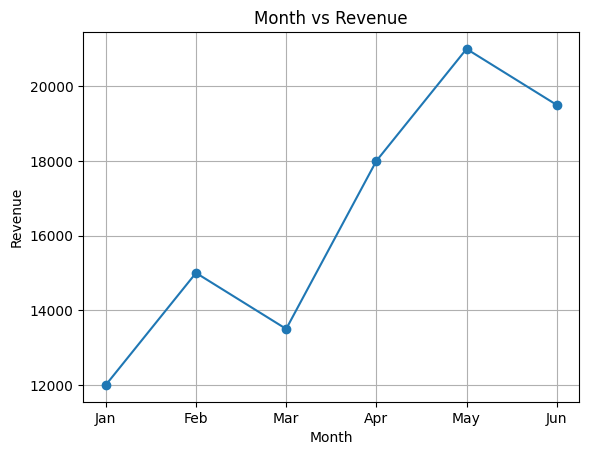

In [403]:
plt.plot(
    monthly_sales_df["Month"],
    monthly_sales_df["Revenue"],
    marker="o"
)

plt.title("Month vs Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid()
plt.show()

#10. Product revenue chart (Pandas + Matplotlib)

Text(0.5, 1.0, 'Revenue vs Product')

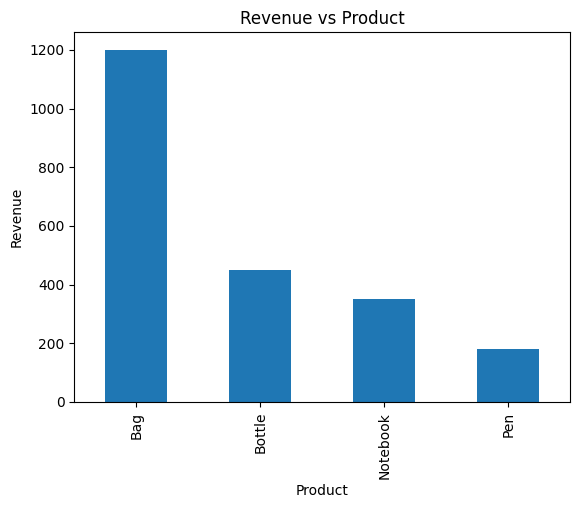

In [404]:
product_revenue = sales_df.groupby('Product')['Revenue'].sum(); product_revenue.plot(kind='bar',ylabel="Revenue")
plt.title("Revenue vs Product")

In [379]:
# Two Insights
# 1. Bag generated the highest revenue of rs 1,200.
# 2. Pen generated the lowest revenue of rs 180.
